Mounted at /content/drive
[Info] Geometría cargada desde: ArcGIS FeatureServer - alcaldías CDMX (16/16 alcaldías reconocidas, columna 'NOMBRE').

Mapa guardado en: /content/drive/MyDrive/Seguridad/mapa_inseguridad_marzo_2020.png


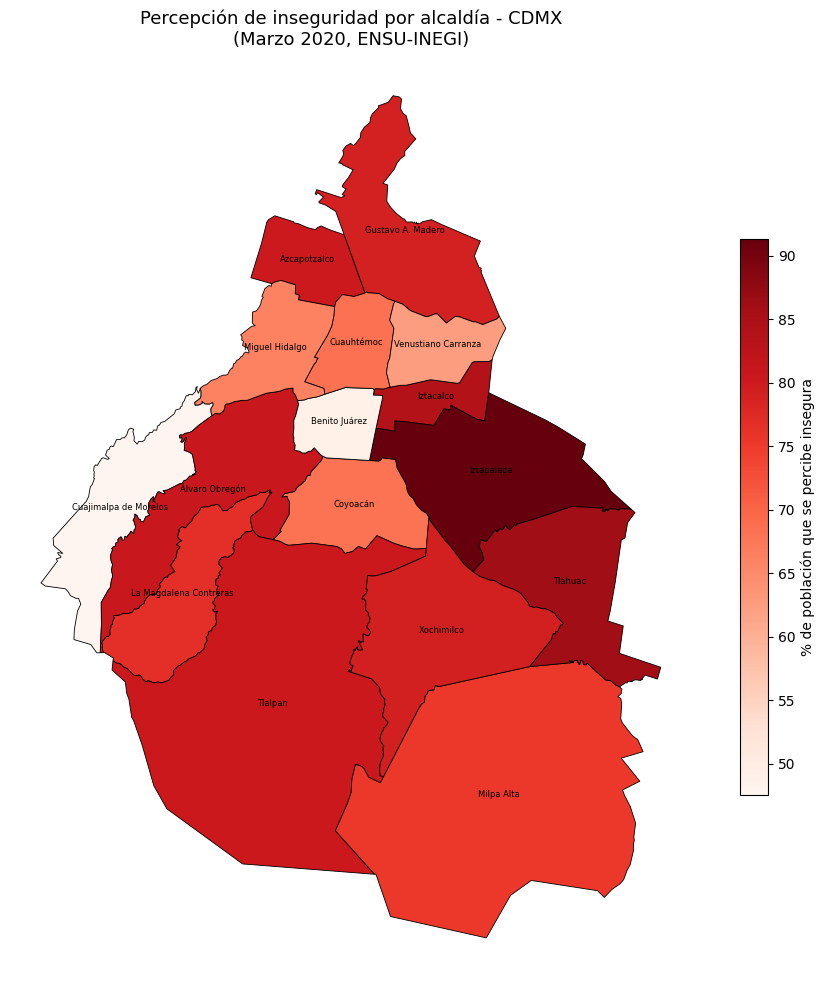

In [1]:
# =============================================================================
# Mapa de percepción de inseguridad por alcaldía - Ciudad de México
# Lee el CSV que ya generamos (percepcion_seguridad_alcaldias_cdmx.csv),
# lo cruza con los polígonos geográficos de las 16 alcaldías y colorea el
# mapa según el % de población que se percibe INSEGURA, para el periodo
# que elijas (por defecto: marzo de 2020).
# =============================================================================

# -----------------------------------------------------------------------
# PASO 0. Librerías (geopandas no viene preinstalado en Colab)
# -----------------------------------------------------------------------
# !pip install geopandas -q      # <-- descomenta y corre esta línea primero
#                                    si estás en una sesión nueva de Colab

import os
import unicodedata
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')


# -----------------------------------------------------------------------
# PASO 1. Parámetros: qué periodo quieres mapear y dónde está tu CSV
# -----------------------------------------------------------------------

ANIO_OBJETIVO = 2020
MES_OBJETIVO = "marzo"          # debe coincidir con la columna "mes" del CSV
COLUMNA_A_COLOREAR = "inseguro_pct"   # también podrías usar "seguro_pct"

CSV_PATH = "/content/drive/MyDrive/Seguridad/percepcion_seguridad_alcaldias_cdmx.csv"

# Carpeta donde se guardará el mapa (PNG)
CARPETA_SALIDA = os.path.dirname(CSV_PATH)
SALIDA_PNG = os.path.join(
    CARPETA_SALIDA, f"mapa_inseguridad_{MES_OBJETIVO}_{ANIO_OBJETIVO}.png"
)


# -----------------------------------------------------------------------
# PASO 2. Utilidades para "emparejar" nombres de alcaldías
# -----------------------------------------------------------------------
# Los geojson/shapefiles públicos y nuestro CSV no siempre escriben los
# nombres exactamente igual (acentos, mayúsculas, puntos). Por eso
# normalizamos ambos lados antes de cruzar la información.

ALCALDIAS_CDMX = [
    "Álvaro Obregón", "Azcapotzalco", "Benito Juárez", "Coyoacán",
    "Cuajimalpa de Morelos", "Cuauhtémoc", "Gustavo A. Madero", "Iztacalco",
    "Iztapalapa", "La Magdalena Contreras", "Miguel Hidalgo", "Milpa Alta",
    "Tláhuac", "Tlalpan", "Venustiano Carranza", "Xochimilco",
]

def normalizar(texto):
    """
    Deja el texto en MAYÚSCULAS, sin acentos y sin puntos, para poder
    comparar 'Álvaro Obregón' con 'ALVARO OBREGON' o 'Alvaro Obregon.'
    """
    texto = str(texto).strip().upper()
    texto = "".join(
        c for c in unicodedata.normalize("NFD", texto)
        if unicodedata.category(c) != "Mn"
    )
    texto = texto.replace(".", "")
    return " ".join(texto.split())

ALCALDIAS_NORM = {normalizar(a): a for a in ALCALDIAS_CDMX}


def detectar_columna_nombre(gdf):
    """
    El geojson/shapefile de alcaldías puede traer el nombre en una columna
    llamada 'NOMBRE', 'NOM_MUN', 'ALCALDIA', 'name', etc. En vez de
    adivinar el nombre exacto, probamos TODAS las columnas de texto y nos
    quedamos con la que más nombres de alcaldías reconozca.
    """
    mejor_columna, mejor_conteo = None, 0
    for col in gdf.columns:
        if gdf[col].dtype != object:
            continue
        conteo = gdf[col].map(normalizar).isin(ALCALDIAS_NORM).sum()
        if conteo > mejor_conteo:
            mejor_columna, mejor_conteo = col, conteo
    return mejor_columna, mejor_conteo


# -----------------------------------------------------------------------
# PASO 3. Descargar (o cargar localmente) los polígonos de las alcaldías
# -----------------------------------------------------------------------
# Intentamos varias fuentes públicas en cascada. Si en tu sesión de Colab
# ninguna responde (o cambió de URL), descarga tú mismo el shapefile/geojson
# de https://datos.cdmx.gob.mx/dataset/alcaldias, súbelo a la misma carpeta
# de Drive, y pon su ruta en RUTA_GEOJSON_LOCAL.

RUTA_GEOJSON_LOCAL = None  # ej: "/content/drive/MyDrive/Seguridad/alcaldias.geojson"

FUENTES_GEOMETRIA = [
    ("ArcGIS FeatureServer - alcaldías CDMX",
     "https://services3.arcgis.com/lJPpeQVgQ9Gdmm11/ArcGIS/rest/services/"
     "alcaldias_cdmx/FeatureServer/0/query?where=1=1&outFields=*&f=geojson"),
    ("Datos Abiertos CDMX (Marco Geoestadístico, alcaldías)",
     "https://datos.cdmx.gob.mx/dataset/alcaldias/resource/"
     "8648431b-4f34-4f1a-a4b1-19142f944300/download"),
]


def cargar_geometria_alcaldias():
    # 1) archivo local, si el usuario ya lo puso a mano
    if RUTA_GEOJSON_LOCAL and os.path.exists(RUTA_GEOJSON_LOCAL):
        gdf = gpd.read_file(RUTA_GEOJSON_LOCAL)
        col, conteo = detectar_columna_nombre(gdf)
        if conteo >= 14:
            print(f"[Info] Geometría cargada desde archivo local ({conteo}/16 alcaldías reconocidas).")
            return gdf, col

    # 2) fuentes públicas en línea
    for nombre_fuente, url in FUENTES_GEOMETRIA:
        try:
            gdf = gpd.read_file(url)
            col, conteo = detectar_columna_nombre(gdf)
            if conteo >= 14:   # tolera un par de nombres raros
                print(f"[Info] Geometría cargada desde: {nombre_fuente} "
                      f"({conteo}/16 alcaldías reconocidas, columna '{col}').")
                return gdf, col
            else:
                print(f"[Aviso] '{nombre_fuente}' respondió pero solo reconocí "
                      f"{conteo}/16 alcaldías; se prueba la siguiente fuente.")
        except Exception as e:
            print(f"[Aviso] No se pudo usar '{nombre_fuente}': {e}")

    raise RuntimeError(
        "No se pudo obtener automáticamente la geometría de las alcaldías.\n"
        "Descarga el shapefile/geojson manualmente desde "
        "https://datos.cdmx.gob.mx/dataset/alcaldias, súbelo a Drive y "
        "define RUTA_GEOJSON_LOCAL con esa ruta."
    )


# -----------------------------------------------------------------------
# PASO 4. Cargar el CSV y quedarnos con el periodo que nos interesa
# -----------------------------------------------------------------------

def cargar_datos_periodo(csv_path, anio, mes):
    df = pd.read_csv(csv_path)
    df_periodo = df[(df["anio"] == anio) & (df["mes"].str.lower() == mes.lower())].copy()

    if df_periodo.empty:
        periodos_disponibles = (
            df[["anio", "mes"]].drop_duplicates().sort_values(["anio", "mes"])
        )
        raise ValueError(
            f"No hay datos para {mes} {anio} en el CSV. "
            f"Periodos disponibles:\n{periodos_disponibles.to_string(index=False)}"
        )

    if len(df_periodo) != 16:
        print(f"[Aviso] Se esperaban 16 alcaldías para {mes} {anio}, "
              f"pero el CSV trae {len(df_periodo)}.")

    df_periodo["alcaldia_norm"] = df_periodo["alcaldia"].map(normalizar)
    return df_periodo


# -----------------------------------------------------------------------
# PASO 5. Cruzar geometría + datos, y dibujar el mapa
# -----------------------------------------------------------------------

def generar_mapa(anio, mes, columna_valor=COLUMNA_A_COLOREAR, guardar_en=SALIDA_PNG):
    gdf, columna_nombre = cargar_geometria_alcaldias()
    gdf = gdf.copy()
    gdf["alcaldia_norm"] = gdf[columna_nombre].map(normalizar)

    df_periodo = cargar_datos_periodo(CSV_PATH, anio, mes)

    gdf_final = gdf.merge(df_periodo, on="alcaldia_norm", how="left")

    faltantes = gdf_final[gdf_final[columna_valor].isna()]
    if not faltantes.empty:
        print("[Aviso] Estas alcaldías del mapa NO se pudieron cruzar con el CSV "
              "(quedarán en gris):")
        print(faltantes[columna_nombre].tolist())

    # --- Dibujo del mapa ---
    fig, ax = plt.subplots(1, 1, figsize=(10, 10))

    gdf_final.plot(
        column=columna_valor,
        cmap="Reds",
        linewidth=0.6,
        edgecolor="black",
        legend=True,
        legend_kwds={"label": "% de población que se percibe insegura", "shrink": 0.6},
        missing_kwds={"color": "lightgrey", "hatch": "///", "label": "Sin dato"},
        ax=ax,
    )

    # Etiquetas con el nombre de cada alcaldía sobre su centroide
    for _, fila in gdf_final.iterrows():
        centro = fila["geometry"].centroid
        ax.annotate(
            text=fila[columna_nombre],
            xy=(centro.x, centro.y),
            ha="center", fontsize=6, color="black",
        )

    ax.set_title(
        f"Percepción de inseguridad por alcaldía - CDMX\n({mes.capitalize()} {anio}, ENSU-INEGI)",
        fontsize=13,
    )
    ax.axis("off")

    plt.tight_layout()
    plt.savefig(guardar_en, dpi=200, bbox_inches="tight")
    print(f"\nMapa guardado en: {guardar_en}")
    plt.show()

    return gdf_final


# -----------------------------------------------------------------------
# PASO 6. Ejecutar
# -----------------------------------------------------------------------

if __name__ == "__main__":
    gdf_resultado = generar_mapa(ANIO_OBJETIVO, MES_OBJETIVO)

In [2]:
# =============================================================================
# Mapa INTERACTIVO de percepción de inseguridad por alcaldía - CDMX
# Igual que el script anterior, pero en vez de fijar año/mes a mano, aquí
# aparecen dos menús desplegables (año y trimestre). Cada vez que cambias
# la selección, el mapa se vuelve a dibujar solo, sin tener que correr la
# celda de nuevo.
# =============================================================================

# -----------------------------------------------------------------------
# PASO 0. Librerías
# -----------------------------------------------------------------------
# !pip install geopandas -q      # <-- descomenta y corre esta línea primero
#                                    si estás en una sesión nueva de Colab

import os
import unicodedata
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

from google.colab import drive
drive.mount('/content/drive')


# -----------------------------------------------------------------------
# PASO 1. Parámetros generales
# -----------------------------------------------------------------------

CSV_PATH = "/content/drive/MyDrive/Seguridad/percepcion_seguridad_alcaldias_cdmx.csv"
COLUMNA_A_COLOREAR = "inseguro_pct"     # también podrías usar "seguro_pct"
RUTA_GEOJSON_LOCAL = None               # ej: ".../alcaldias.geojson", si la geometría
                                         # no se pudo descargar automáticamente

ORDEN_MESES = ["marzo", "junio", "septiembre", "diciembre"]  # orden lógico T1..T4


# -----------------------------------------------------------------------
# PASO 2. Normalización de nombres (para cruzar CSV <-> geometría)
# -----------------------------------------------------------------------

ALCALDIAS_CDMX = [
    "Álvaro Obregón", "Azcapotzalco", "Benito Juárez", "Coyoacán",
    "Cuajimalpa de Morelos", "Cuauhtémoc", "Gustavo A. Madero", "Iztacalco",
    "Iztapalapa", "La Magdalena Contreras", "Miguel Hidalgo", "Milpa Alta",
    "Tláhuac", "Tlalpan", "Venustiano Carranza", "Xochimilco",
]

def normalizar(texto):
    """MAYÚSCULAS, sin acentos, sin puntos: 'Álvaro Obregón' == 'ALVARO OBREGON'"""
    texto = str(texto).strip().upper()
    texto = "".join(
        c for c in unicodedata.normalize("NFD", texto)
        if unicodedata.category(c) != "Mn"
    )
    texto = texto.replace(".", "")
    return " ".join(texto.split())

ALCALDIAS_NORM = {normalizar(a) for a in ALCALDIAS_CDMX}


def detectar_columna_nombre(gdf):
    """Encuentra qué columna del geojson trae el nombre de la alcaldía."""
    mejor_columna, mejor_conteo = None, 0
    for col in gdf.columns:
        if gdf[col].dtype != object:
            continue
        conteo = gdf[col].map(normalizar).isin(ALCALDIAS_NORM).sum()
        if conteo > mejor_conteo:
            mejor_columna, mejor_conteo = col, conteo
    return mejor_columna, mejor_conteo


# -----------------------------------------------------------------------
# PASO 3. Cargar la geometría UNA sola vez (se reutiliza en cada refresco
#          del mapa, para no volver a descargarla cada vez que cambias
#          el año o el trimestre)
# -----------------------------------------------------------------------

FUENTES_GEOMETRIA = [
    ("ArcGIS FeatureServer - alcaldías CDMX",
     "https://services3.arcgis.com/lJPpeQVgQ9Gdmm11/ArcGIS/rest/services/"
     "alcaldias_cdmx/FeatureServer/0/query?where=1=1&outFields=*&f=geojson"),
    ("Datos Abiertos CDMX (Marco Geoestadístico, alcaldías)",
     "https://datos.cdmx.gob.mx/dataset/alcaldias/resource/"
     "8648431b-4f34-4f1a-a4b1-19142f944300/download"),
]

def cargar_geometria_alcaldias():
    if RUTA_GEOJSON_LOCAL and os.path.exists(RUTA_GEOJSON_LOCAL):
        gdf = gpd.read_file(RUTA_GEOJSON_LOCAL)
        col, conteo = detectar_columna_nombre(gdf)
        if conteo >= 14:
            print(f"[Info] Geometría cargada desde archivo local ({conteo}/16 alcaldías).")
            return gdf, col

    for nombre_fuente, url in FUENTES_GEOMETRIA:
        try:
            gdf = gpd.read_file(url)
            col, conteo = detectar_columna_nombre(gdf)
            if conteo >= 14:
                print(f"[Info] Geometría cargada desde: {nombre_fuente} "
                      f"({conteo}/16 alcaldías, columna '{col}').")
                return gdf, col
            print(f"[Aviso] '{nombre_fuente}' respondió pero solo reconocí "
                  f"{conteo}/16 alcaldías; se prueba la siguiente fuente.")
        except Exception as e:
            print(f"[Aviso] No se pudo usar '{nombre_fuente}': {e}")

    raise RuntimeError(
        "No se pudo obtener la geometría de las alcaldías automáticamente.\n"
        "Descárgala de https://datos.cdmx.gob.mx/dataset/alcaldias, súbela a "
        "Drive y define RUTA_GEOJSON_LOCAL con esa ruta."
    )


# -----------------------------------------------------------------------
# PASO 4. Cargar el CSV completo UNA sola vez
# -----------------------------------------------------------------------

def cargar_csv(csv_path):
    df = pd.read_csv(csv_path)
    df["alcaldia_norm"] = df["alcaldia"].map(normalizar)
    df["mes"] = df["mes"].str.lower()
    return df


# Estas dos cargas pesadas se hacen UNA vez al iniciar; los dropdowns
# solo filtran/redibujan sobre lo que ya está en memoria.
print("Cargando geometría de las alcaldías...")
GDF_ALCALDIAS, COL_NOMBRE = cargar_geometria_alcaldias()

print("Cargando el CSV de percepción de inseguridad...")
DF_COMPLETO = cargar_csv(CSV_PATH)


# -----------------------------------------------------------------------
# PASO 5. Función que dibuja el mapa para un (año, mes) dado
# -----------------------------------------------------------------------

def dibujar_mapa(anio, mes, columna_valor=COLUMNA_A_COLOREAR):
    df_periodo = DF_COMPLETO[
        (DF_COMPLETO["anio"] == anio) & (DF_COMPLETO["mes"] == mes.lower())
    ].copy()

    if df_periodo.empty:
        print(f"No hay datos en el CSV para {mes} {anio}.")
        return

    gdf_final = GDF_ALCALDIAS.merge(df_periodo, on="alcaldia_norm", how="left")

    faltantes = gdf_final[gdf_final[columna_valor].isna()]
    if not faltantes.empty:
        print("[Aviso] Sin dato para (quedan en gris):",
              faltantes[COL_NOMBRE].tolist())

    fig, ax = plt.subplots(1, 1, figsize=(9, 9))
    gdf_final.plot(
        column=columna_valor,
        cmap="Reds",
        linewidth=0.6,
        edgecolor="black",
        legend=True,
        legend_kwds={"label": "% de población que se percibe insegura", "shrink": 0.6},
        missing_kwds={"color": "lightgrey", "hatch": "///", "label": "Sin dato"},
        vmin=DF_COMPLETO[columna_valor].min(),   # misma escala de color siempre,
        vmax=DF_COMPLETO[columna_valor].max(),   # para poder comparar entre periodos
        ax=ax,
    )

    for _, fila in gdf_final.iterrows():
        centro = fila["geometry"].centroid
        ax.annotate(fila[COL_NOMBRE], xy=(centro.x, centro.y),
                    ha="center", fontsize=6, color="black")

    ax.set_title(
        f"Percepción de inseguridad por alcaldía - CDMX\n({mes.capitalize()} {anio}, ENSU-INEGI)",
        fontsize=13,
    )
    ax.axis("off")
    plt.tight_layout()
    plt.show()


# -----------------------------------------------------------------------
# PASO 6. Widgets interactivos: dropdown de año + dropdown de trimestre
# -----------------------------------------------------------------------

anios_disponibles = sorted(DF_COMPLETO["anio"].unique())
meses_disponibles = [m for m in ORDEN_MESES if m in DF_COMPLETO["mes"].unique()]

dropdown_anio = widgets.Dropdown(
    options=anios_disponibles,
    value=anios_disponibles[-1],
    description="Año:",
)

dropdown_trimestre = widgets.Dropdown(
    options=meses_disponibles,
    value=meses_disponibles[0],
    description="Trimestre:",
)

salida = widgets.Output()

def actualizar(change=None):
    with salida:
        clear_output(wait=True)
        dibujar_mapa(dropdown_anio.value, dropdown_trimestre.value)

dropdown_anio.observe(actualizar, names="value")
dropdown_trimestre.observe(actualizar, names="value")

display(widgets.HBox([dropdown_anio, dropdown_trimestre]), salida)
actualizar()   # dibuja el mapa inicial

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cargando geometría de las alcaldías...
[Info] Geometría cargada desde: ArcGIS FeatureServer - alcaldías CDMX (16/16 alcaldías, columna 'NOMBRE').
Cargando el CSV de percepción de inseguridad...


Output()

In [3]:
# =============================================================================
# Mapa INTERACTIVO de percepción de inseguridad por alcaldía - CDMX
# Igual que el script anterior, pero en vez de fijar año/mes a mano, aquí
# aparecen dos menús desplegables (año y trimestre). Cada vez que cambias
# la selección, el mapa se vuelve a dibujar solo, sin tener que correr la
# celda de nuevo.
# =============================================================================

# -----------------------------------------------------------------------
# PASO 0. Librerías
# -----------------------------------------------------------------------
# !pip install geopandas -q      # <-- descomenta y corre esta línea primero
#                                    si estás en una sesión nueva de Colab

import os
import unicodedata
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

from google.colab import drive
drive.mount('/content/drive')


# -----------------------------------------------------------------------
# PASO 1. Parámetros generales
# -----------------------------------------------------------------------

CSV_PATH = "/content/drive/MyDrive/Seguridad/percepcion_seguridad_alcaldias_cdmx.csv"
COLUMNA_A_COLOREAR = "inseguro_pct"     # también podrías usar "seguro_pct"
RUTA_GEOJSON_LOCAL = None               # ej: ".../alcaldias.geojson", si la geometría
                                         # no se pudo descargar automáticamente

ORDEN_MESES = ["marzo", "junio", "septiembre", "diciembre"]  # orden lógico T1..T4


# -----------------------------------------------------------------------
# PASO 2. Normalización de nombres (para cruzar CSV <-> geometría)
# -----------------------------------------------------------------------

ALCALDIAS_CDMX = [
    "Álvaro Obregón", "Azcapotzalco", "Benito Juárez", "Coyoacán",
    "Cuajimalpa de Morelos", "Cuauhtémoc", "Gustavo A. Madero", "Iztacalco",
    "Iztapalapa", "La Magdalena Contreras", "Miguel Hidalgo", "Milpa Alta",
    "Tláhuac", "Tlalpan", "Venustiano Carranza", "Xochimilco",
]

def normalizar(texto):
    """MAYÚSCULAS, sin acentos, sin puntos: 'Álvaro Obregón' == 'ALVARO OBREGON'"""
    texto = str(texto).strip().upper()
    texto = "".join(
        c for c in unicodedata.normalize("NFD", texto)
        if unicodedata.category(c) != "Mn"
    )
    texto = texto.replace(".", "")
    return " ".join(texto.split())

ALCALDIAS_NORM = {normalizar(a) for a in ALCALDIAS_CDMX}


def detectar_columna_nombre(gdf):
    """Encuentra qué columna del geojson trae el nombre de la alcaldía."""
    mejor_columna, mejor_conteo = None, 0
    for col in gdf.columns:
        if gdf[col].dtype != object:
            continue
        conteo = gdf[col].map(normalizar).isin(ALCALDIAS_NORM).sum()
        if conteo > mejor_conteo:
            mejor_columna, mejor_conteo = col, conteo
    return mejor_columna, mejor_conteo


# -----------------------------------------------------------------------
# PASO 3. Cargar la geometría UNA sola vez (se reutiliza en cada refresco
#          del mapa, para no volver a descargarla cada vez que cambias
#          el año o el trimestre)
# -----------------------------------------------------------------------

FUENTES_GEOMETRIA = [
    ("ArcGIS FeatureServer - alcaldías CDMX",
     "https://services3.arcgis.com/lJPpeQVgQ9Gdmm11/ArcGIS/rest/services/"
     "alcaldias_cdmx/FeatureServer/0/query?where=1=1&outFields=*&f=geojson"),
    ("Datos Abiertos CDMX (Marco Geoestadístico, alcaldías)",
     "https://datos.cdmx.gob.mx/dataset/alcaldias/resource/"
     "8648431b-4f34-4f1a-a4b1-19142f944300/download"),
]

def cargar_geometria_alcaldias():
    if RUTA_GEOJSON_LOCAL and os.path.exists(RUTA_GEOJSON_LOCAL):
        gdf = gpd.read_file(RUTA_GEOJSON_LOCAL)
        col, conteo = detectar_columna_nombre(gdf)
        if conteo >= 14:
            print(f"[Info] Geometría cargada desde archivo local ({conteo}/16 alcaldías).")
            return gdf, col

    for nombre_fuente, url in FUENTES_GEOMETRIA:
        try:
            gdf = gpd.read_file(url)
            col, conteo = detectar_columna_nombre(gdf)
            if conteo >= 14:
                print(f"[Info] Geometría cargada desde: {nombre_fuente} "
                      f"({conteo}/16 alcaldías, columna '{col}').")
                return gdf, col
            print(f"[Aviso] '{nombre_fuente}' respondió pero solo reconocí "
                  f"{conteo}/16 alcaldías; se prueba la siguiente fuente.")
        except Exception as e:
            print(f"[Aviso] No se pudo usar '{nombre_fuente}': {e}")

    raise RuntimeError(
        "No se pudo obtener la geometría de las alcaldías automáticamente.\n"
        "Descárgala de https://datos.cdmx.gob.mx/dataset/alcaldias, súbela a "
        "Drive y define RUTA_GEOJSON_LOCAL con esa ruta."
    )


# -----------------------------------------------------------------------
# PASO 4. Cargar el CSV completo UNA sola vez
# -----------------------------------------------------------------------

def cargar_csv(csv_path):
    df = pd.read_csv(csv_path)
    df["alcaldia_norm"] = df["alcaldia"].map(normalizar)
    df["mes"] = df["mes"].str.lower()
    return df


# Estas dos cargas pesadas se hacen UNA vez al iniciar; los dropdowns
# solo filtran/redibujan sobre lo que ya está en memoria.
print("Cargando geometría de las alcaldías...")
GDF_ALCALDIAS, COL_NOMBRE = cargar_geometria_alcaldias()
GDF_ALCALDIAS["alcaldia_norm"] = GDF_ALCALDIAS[COL_NOMBRE].map(normalizar)

print("Cargando el CSV de percepción de inseguridad...")
DF_COMPLETO = cargar_csv(CSV_PATH)


# -----------------------------------------------------------------------
# PASO 5. Función que dibuja el mapa para un (año, mes) dado
# -----------------------------------------------------------------------

def dibujar_mapa(anio, mes, columna_valor=COLUMNA_A_COLOREAR):
    df_periodo = DF_COMPLETO[
        (DF_COMPLETO["anio"] == anio) & (DF_COMPLETO["mes"] == mes.lower())
    ].copy()

    if df_periodo.empty:
        print(f"No hay datos en el CSV para {mes} {anio}.")
        return

    gdf_final = GDF_ALCALDIAS.merge(df_periodo, on="alcaldia_norm", how="left")

    faltantes = gdf_final[gdf_final[columna_valor].isna()]
    if not faltantes.empty:
        print("[Aviso] Sin dato para (quedan en gris):",
              faltantes[COL_NOMBRE].tolist())

    fig, ax = plt.subplots(1, 1, figsize=(9, 9))
    gdf_final.plot(
        column=columna_valor,
        cmap="Reds",
        linewidth=0.6,
        edgecolor="black",
        legend=True,
        legend_kwds={"label": "% de población que se percibe insegura", "shrink": 0.6},
        missing_kwds={"color": "lightgrey", "hatch": "///", "label": "Sin dato"},
        vmin=DF_COMPLETO[columna_valor].min(),   # misma escala de color siempre,
        vmax=DF_COMPLETO[columna_valor].max(),   # para poder comparar entre periodos
        ax=ax,
    )

    for _, fila in gdf_final.iterrows():
        centro = fila["geometry"].centroid
        ax.annotate(fila[COL_NOMBRE], xy=(centro.x, centro.y),
                    ha="center", fontsize=6, color="black")

    ax.set_title(
        f"Percepción de inseguridad por alcaldía - CDMX\n({mes.capitalize()} {anio}, ENSU-INEGI)",
        fontsize=13,
    )
    ax.axis("off")
    plt.tight_layout()
    plt.show()


# -----------------------------------------------------------------------
# PASO 6. Widgets interactivos: dropdown de año + dropdown de trimestre
# -----------------------------------------------------------------------

anios_disponibles = sorted(DF_COMPLETO["anio"].unique())
meses_disponibles = [m for m in ORDEN_MESES if m in DF_COMPLETO["mes"].unique()]

dropdown_anio = widgets.Dropdown(
    options=anios_disponibles,
    value=anios_disponibles[-1],
    description="Año:",
)

dropdown_trimestre = widgets.Dropdown(
    options=meses_disponibles,
    value=meses_disponibles[0],
    description="Trimestre:",
)

salida = widgets.Output()

def actualizar(change=None):
    with salida:
        clear_output(wait=True)
        dibujar_mapa(dropdown_anio.value, dropdown_trimestre.value)

dropdown_anio.observe(actualizar, names="value")
dropdown_trimestre.observe(actualizar, names="value")

display(widgets.HBox([dropdown_anio, dropdown_trimestre]), salida)
actualizar()   # dibuja el mapa inicial

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cargando geometría de las alcaldías...
[Info] Geometría cargada desde: ArcGIS FeatureServer - alcaldías CDMX (16/16 alcaldías, columna 'NOMBRE').
Cargando el CSV de percepción de inseguridad...


Output()